# Detecting AI-generated images under generator shift

COMP 671 Deep Learning, final project.

**Question.** A detector is trained on real photos and fakes from ONE generator (Stable Diffusion 1.5). Does it still work on images from generators it has never seen?

**Plan.** Load the data, check it, clean and preprocess it, split it into train / validation / test, train three models (a CNN, a ResNet, and a CNN that looks at diffusion-model residuals), tune their hyperparameters on the validation set, test them on SD15 and on six unseen generators, check whether the models mostly follow how sharp the pictures are, and summarize.

Run the cells from top to bottom. All settings are in `config.yaml`. The first run streams the dataset from Hugging Face (a few minutes) and the whole notebook takes roughly 15 to 30 minutes on a laptop CPU. The sampled 32x32 images are saved in `data/`, so the next run skips the streaming.

In [103]:
# ---------- Step 1: imports and settings ----------

import os
import io
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split


# the notebook lives in notebooks/, everything else is one folder up
ROOT = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
for folder in ["data", "models", "results/tables", "results/figures"]:
    os.makedirs(f"{ROOT}/{folder}", exist_ok=True)

# all settings come from config.yaml
cfg = yaml.safe_load(open(f"{ROOT}/config.yaml"))
SEED = cfg["seed"]
SEEN = cfg["train_generator"]
UNSEEN = cfg["unseen_generators"]

np.random.seed(SEED)
torch.manual_seed(SEED)

print("torch", torch.__version__)
print("train on:", SEEN)
print("test also on:", UNSEEN)

torch 2.14.1
train on: SD15
test also on: ['Midjourney', 'ADM', 'BigGAN', 'GLIDE', 'VQDM', 'Wukong']


In [104]:
# ---------- Step 2: load the dataset ----------

# The dataset is big and its rows are NOT in random order, so taking the first N rows would
# give a biased sample. Instead I stream through the whole thing once and keep a random sample
# of every generator (reservoir sampling: every row has the same chance of being kept).
# Each kept image is cropped to a square and shrunk to 32x32 the same way for real and fake images.

images_file = f"{ROOT}/data/images_32x32.npy"
table_file = f"{ROOT}/data/image_table.csv"


def to_32x32(img, size=cfg["image_size"]):
    img = img.convert("RGB")
    side = min(img.size)
    left = (img.width - side) // 2
    top = (img.height - side) // 2
    img = img.crop((left, top, left + side, top + side))
    return np.array(img.resize((size, size), Image.BICUBIC))


if os.path.exists(images_file) and os.path.exists(table_file):
    # already done in an earlier run
    images = np.load(images_file)
    df = pd.read_csv(table_file)
    print("loaded the saved sample:", images.shape)

else:
    import time
    from datasets import load_dataset, Image as HFImage

    ds = load_dataset(cfg["dataset"], split="train", streaming=True)
    names = ds.features["generator"].names
    ds = ds.cast_column("image", HFImage(decode=False))    # keep the raw bytes, only decode the images we keep

    # how many images we want from each generator
    want = {"Real": cfg["real_images"], SEEN: cfg["seen_images"]}
    for g in UNSEEN:
        want[g] = cfg["unseen_images"]

    kept = {g: [] for g in want}            # the sample of each generator
    passed = {g: 0 for g in want}           # rows of that generator we have gone past so far
    rows_in_dataset = {}                    # rows per generator, just for information
    bad_images = 0
    rng = np.random.default_rng(SEED)
    start = time.time()

    for row_number, row in enumerate(ds):
        if row_number % 2000 == 0:
            print(f"row {row_number:,}   ({(time.time() - start) / 60:.1f} min)")

        gen = names[row["generator"]]
        rows_in_dataset[gen] = rows_in_dataset.get(gen, 0) + 1
        if gen not in want:
            continue

        passed[gen] += 1
        k = passed[gen]
        if k <= want[gen]:
            slot = k - 1                        # the sample is still filling up
        else:
            slot = int(rng.integers(0, k))      # keep this row with probability want/k
            if slot >= want[gen]:
                continue

        try:
            img = Image.open(io.BytesIO(row["image"]["bytes"]))
            item = (to_32x32(img), gen, row["label"], img.width, img.height, img.format, row_number)
        except Exception:
            bad_images += 1
            continue

        if slot < len(kept[gen]):
            kept[gen][slot] = item              # replace an older image
        else:
            kept[gen].append(item)

    # one image array and one table, in the same order
    all_items = [item for g in want for item in kept[g]]
    images = np.stack([item[0] for item in all_items])
    df = pd.DataFrame([item[1:] for item in all_items],
                      columns=["generator", "label", "native_w", "native_h", "format", "row_number"])

    np.save(images_file, images)
    df.to_csv(table_file, index=False)

    print("\nrows in the dataset per generator:", rows_in_dataset)
    print("images that could not be read:", bad_images)
    print("kept:", images.shape)

loaded the saved sample: (3800, 32, 32, 3)


In [105]:
# ---------- Step 3: check the data ----------

print("table (rows, columns):", df.shape)
print("image array:", images.shape, images.dtype)
print()

# first rows and column types
display(df.head())
df.info()

# mean, median, min and max of the ORIGINAL image sizes (before the shrink to 32x32)
display(df[["native_w", "native_h"]].describe())

# missing values, duplicates, broken images
print("\nmissing values per column:")
print(df.isnull().sum())

flat = images.reshape(len(images), -1)
print("\nduplicate images:", len(images) - len(np.unique(flat, axis=0)))
print("single-colour images:", int((flat.std(axis=1) == 0).sum()))

# images per generator, and do the labels (0 = real, 1 = fake) match the generator names?
print("\nlabel against generator:")
display(pd.crosstab(df["generator"], df["label"]))

# Real photos come in many sizes, generated images are usually one fixed size.
# A model could learn that instead of the generator, so look at it now.
size_table = df.groupby("generator").agg(
    median_width=("native_w", "median"),
    min_width=("native_w", "min"),
    max_width=("native_w", "max"),
    share_jpeg=("format", lambda s: (s == "JPEG").mean()),
)
display(size_table)
size_table.to_csv(f"{ROOT}/results/tables/original_sizes.csv")

table (rows, columns): (3800, 7)
image array: (3800, 32, 32, 3) uint8



,generator,label,native_w,native_h,format,row_number,split
0,Real,0,500,400,JPEG,8488,train
1,Real,0,500,333,JPEG,5508,test
2,Real,0,650,488,JPEG,11934,train
3,Real,0,500,338,JPEG,27618,train
4,Real,0,300,221,JPEG,22492,test


<class 'pandas.DataFrame'>
RangeIndex: 3800 entries, 0 to 3799
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   generator   3800 non-null   str  
 1   label       3800 non-null   int64
 2   native_w    3800 non-null   int64
 3   native_h    3800 non-null   int64
 4   format      3800 non-null   str  
 5   row_number  3800 non-null   int64
 6   split       3800 non-null   str  
dtypes: int64(4), str(3)
memory usage: 253.4 KB


,native_w,native_h
count,3800.000000,3800.000000
mean,449.449737,431.934737
std,240.813916,237.637755
min,34.000000,38.000000
25%,256.000000,256.000000
50%,500.000000,440.500000
75%,512.000000,512.000000
max,4786.000000,4419.000000



missing values per column:
generator     0
label         0
native_w      0
native_h      0
format        0
row_number    0
split         0
dtype: int64

duplicate images: 0
single-colour images: 0

label against generator:


label,0,1
generator,,
ADM,0,300
BigGAN,0,300
GLIDE,0,300
Midjourney,0,300
Real,1000,0
SD15,0,1000
VQDM,0,300
Wukong,0,300


,median_width,min_width,max_width,share_jpeg
generator,,,,
ADM,256.0,256,256,0.0
BigGAN,128.0,128,128,0.0
GLIDE,256.0,256,256,0.0
Midjourney,1024.0,1024,1024,0.0
Real,500.0,34,4786,1.0
SD15,512.0,512,512,0.0
VQDM,256.0,256,256,0.0
Wukong,512.0,512,512,0.0


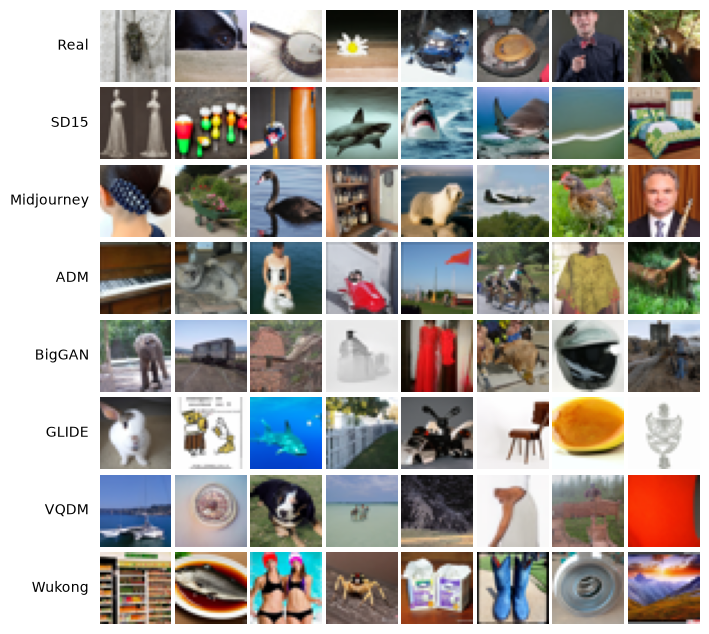

In [106]:
# ---------- Step 3b: look at the pictures ----------

groups_to_show = ["Real", SEEN] + UNSEEN
fig, axes = plt.subplots(len(groups_to_show), 8, figsize=(8, 8))

for row, g in enumerate(groups_to_show):
    positions = df.index[df["generator"] == g][:8]
    for col in range(8):
        axes[row, col].imshow(images[positions[col]])
        axes[row, col].axis("off")
    axes[row, 0].text(-0.15, 0.5, g, transform=axes[row, 0].transAxes, ha="right", va="center", fontsize=10)

fig.subplots_adjust(left=0.15, wspace=0.05, hspace=0.05)
plt.savefig(f"{ROOT}/results/figures/01_sample_images.png", dpi=200, bbox_inches="tight")
plt.show()

In [107]:
# ---------- Step 4: fill missing values and preprocess ----------

# If a column had missing values I would fill them (numbers with the median, text with "unknown").
# The check in Step 3 should show none, this loop is only here to be safe.
for col in df.columns:
    if df[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna("unknown")

print("missing values left:", int(df.isnull().sum().sum()))

# pixels 0..255 -> floats 0..1, and channels first because PyTorch wants (N, 3, 32, 32)
pixels = torch.tensor(images, dtype=torch.float32).permute(0, 3, 1, 2) / 255.0
labels = torch.tensor(df["label"].values, dtype=torch.float32)

print("pixels:", tuple(pixels.shape), "| smallest value", pixels.min().item(), "| largest value", pixels.max().item())
print("fake share:", labels.mean().item())

missing values left: 0
pixels: (3800, 3, 32, 32) | smallest value 0.0 | largest value 1.0
fake share: 0.7368420958518982


In [108]:
# ---------- Step 5: train / validation / test split ----------

# Real photos and SD15 fakes are split at random, half real and half fake in every part.
# The six unseen generators are NEVER used for training or validation, only for the final test.

pool = df.index[df["generator"].isin(["Real", SEEN])].values

train_val_idx, test_pool_idx = train_test_split(
    pool, test_size=cfg["test_per_class"] * 2, stratify=df.loc[pool, "label"], random_state=SEED)

train_idx, val_idx = train_test_split(
    train_val_idx, test_size=cfg["val_per_class"] * 2, stratify=df.loc[train_val_idx, "label"], random_state=SEED)

unseen_idx = df.index[df["generator"].isin(UNSEEN)].values
test_idx = np.concatenate([test_pool_idx, unseen_idx])

df["split"] = "-"
df.loc[train_idx, "split"] = "train"
df.loc[val_idx, "split"] = "val"
df.loc[test_idx, "split"] = "test"

display(pd.crosstab(df["generator"], df["split"]))
df.to_csv(table_file, index=False)        # the saved table now also says which split every image is in

# test set facts used later
test_gen = df["generator"].values[test_idx]
test_y = labels[test_idx].numpy()

split,test,train,val
generator,,,
ADM,300,0,0
BigGAN,300,0,0
GLIDE,300,0,0
Midjourney,300,0,0
Real,300,550,150
SD15,300,550,150
VQDM,300,0,0
Wukong,300,0,0


In [109]:
# ---------- Step 6: the models and the training loop ----------

# Model 1: plain CNN (textbook chapter 10)
class CNN(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 32 -> 16
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 16 -> 8
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 8 -> 4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)


# Model 2: small ResNet (chapter 11), two 3x3 convolutions per block plus a skip connection
class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.relu = nn.ReLU()

        # skip connection: the block input is added back to its output
        # (a 1x1 convolution fixes the shape when the number of channels or the size changes)
        if stride != 1 or in_ch != out_ch:
            self.skip = nn.Conv2d(in_ch, out_ch, 1, stride=stride)
        else:
            self.skip = nn.Identity()

    def forward(self, x):
        out = self.conv2(self.relu(self.conv1(x)))
        return self.relu(out + self.skip(x))


class ResNet(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1), nn.ReLU())
        self.blocks = nn.Sequential(ResBlock(16, 16, 1), ResBlock(16, 32, 2), ResBlock(32, 64, 2))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(64, 1))

    def forward(self, x):
        return self.head(self.blocks(self.stem(x))).squeeze(1)


print("CNN parameters:   ", sum(p.numel() for p in CNN().parameters()))
print("ResNet parameters:", sum(p.numel() for p in ResNet().parameters()))


# Training: Adam, binary cross-entropy, and I keep the weights of the epoch with the lowest validation loss.
def fit(arch, dropout, lr, x_train, y_train, x_val, y_val, seed=0, epochs=cfg["epochs"], batch_size=cfg["batch_size"]):
    torch.manual_seed(seed)                 # the seed fixes the starting weights and the batch order
    model = arch(dropout)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()

    history = {"train_loss": [], "val_loss": []}
    best_loss, best_weights = float("inf"), None

    for epoch in range(epochs):
        # one pass over the training images, in random order
        model.train()
        order = torch.randperm(len(x_train))
        total = 0.0
        for i in range(0, len(order), batch_size):
            batch = order[i:i + batch_size]
            optimizer.zero_grad()
            loss = loss_fn(model(x_train[batch]), y_train[batch])
            loss.backward()
            optimizer.step()
            total += loss.item() * len(batch)

        # validation loss after every epoch
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(x_val), y_val).item()
        history["train_loss"].append(total / len(x_train))
        history["val_loss"].append(val_loss)

        # remember the best epoch so far
        if val_loss < best_loss:
            best_loss = val_loss
            best_weights = {k: v.clone() for k, v in model.state_dict().items()}
            history["best_epoch"] = epoch + 1

    model.load_state_dict(best_weights)
    model.eval()
    return model, history


# probability that each image is fake
def predict(model, x, batch=500):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(x), batch):
            logits = model(x[i:i + batch]).double()      # float64, so very confident scores do not all become exactly 1.0
            out.append(torch.sigmoid(logits))
    return torch.cat(out).numpy()

CNN parameters:    89249
ResNet parameters: 77121


Loading pipeline components...: 100%|██████████| 2/2 [00:00<00:00, 16.93it/s]


t =   50   validation AUROC 0.461
t =  100   validation AUROC 0.479
t =  200   validation AUROC 0.525
t =  300   validation AUROC 0.580
t =  400   validation AUROC 0.616
t =  500   validation AUROC 0.616
t =  700   validation AUROC 0.515
chosen noise level: 400


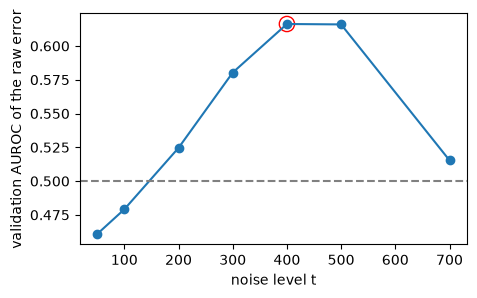

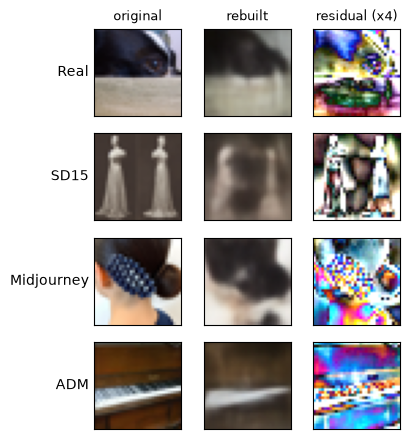

In [110]:
# ---------- Step 7: diffusion residuals (the input of model 3) ----------

# A pretrained diffusion model (DDPM) has only ever seen real photos. I add noise to an image,
# let the model guess the noise, and rebuild the image from that guess.
# Images the model could have made itself should be rebuilt better than other images,
# so the rebuilding error (the "residual") may tell real from generated images apart.
# The model is only used as it is, it is never trained here.

from diffusers import DDPMPipeline

pipe = DDPMPipeline.from_pretrained(cfg["ddpm_model"], low_cpu_mem_usage=False)
unet, scheduler = pipe.unet.eval(), pipe.scheduler


def rebuild(x, t, batch=64):
    # x: images in 0..1, shape (N, 3, 32, 32). Returns the rebuilt images, the absolute error
    # image (residual) and the mean squared error of every image.
    noise = torch.randn(x.shape, generator=torch.Generator().manual_seed(0))
    a = scheduler.alphas_cumprod[t].item()

    rebuilt_all = []
    with torch.no_grad():
        for i in range(0, len(x), batch):
            clean = x[i:i + batch] * 2 - 1                                   # the model works on -1..1
            noisy = a ** 0.5 * clean + (1 - a) ** 0.5 * noise[i:i + batch]
            noise_guess = unet(noisy, torch.full((len(clean),), t)).sample
            rebuilt_all.append((noisy - (1 - a) ** 0.5 * noise_guess) / a ** 0.5)

    rebuilt = torch.cat(rebuilt_all)
    residual = (rebuilt - (x * 2 - 1)).abs()
    return rebuilt, residual, (residual ** 2).mean(dim=(1, 2, 3))


# choose the noise level t on the VALIDATION images only (real + SD15), by how well the raw error separates them
scan = []
for t in cfg["noise_levels"]:
    _, _, err = rebuild(pixels[val_idx], t)
    auc = roc_auc_score(labels[val_idx].numpy(), err.numpy())
    scan.append({"t": t, "val_auroc": auc, "distance_from_chance": abs(auc - 0.5)})
    print(f"t = {t:4d}   validation AUROC {auc:.3f}")

scan = pd.DataFrame(scan)
best_t = int(scan.loc[scan["distance_from_chance"].idxmax(), "t"])
print("chosen noise level:", best_t)
scan.to_csv(f"{ROOT}/results/tables/noise_level_scan.csv", index=False)

# rebuild every image at that level
rebuilt, residual, _ = rebuild(pixels, best_t)

# standardise each colour channel with the mean and std of the TRAINING residuals
mean = residual[train_idx].mean(dim=(0, 2, 3), keepdim=True)
std = residual[train_idx].std(dim=(0, 2, 3), keepdim=True)
residual = (residual - mean) / std

# figure: validation AUROC against the noise level
plt.figure(figsize=(5, 3))
plt.plot(scan["t"], scan["val_auroc"], marker="o")
plt.axhline(0.5, color="grey", linestyle="--")
plt.scatter([best_t], scan.loc[scan["t"] == best_t, "val_auroc"], s=120, facecolors="none", edgecolors="red")
plt.xlabel("noise level t")
plt.ylabel("validation AUROC of the raw error")
plt.savefig(f"{ROOT}/results/figures/02_noise_level_scan.png", dpi=200, bbox_inches="tight")
plt.show()

# figure: one test image per group, original / rebuilt / residual
show = [df.index[(df["generator"] == g) & (df["split"] == "test")][0] for g in ["Real", SEEN, UNSEEN[0], UNSEEN[1]]]
fig, axes = plt.subplots(len(show), 3, figsize=(4, 5.2))
for row, position in enumerate(show):
    axes[row, 0].imshow(images[position])
    axes[row, 1].imshow(((rebuilt[position] + 1) / 2).clamp(0, 1).permute(1, 2, 0).numpy())
    axes[row, 2].imshow((4 * (rebuilt[position] - (pixels[position] * 2 - 1)).abs()).clamp(0, 1).permute(1, 2, 0).numpy())
    axes[row, 0].set_ylabel(df.loc[position, "generator"], rotation=0, ha="right", va="center")
    for ax in axes[row]:
        ax.set_xticks([])
        ax.set_yticks([])
for ax, title in zip(axes[0], ["original", "rebuilt", "residual (x4)"]):
    ax.set_title(title, fontsize=9)
plt.savefig(f"{ROOT}/results/figures/03_diffusion_examples.png", dpi=200, bbox_inches="tight")
plt.show()

In [111]:
# ---------- Step 8: hyperparameter tuning (validation set only) ----------

# The three models. Model 3 is the same CNN as model 1, but its input is the diffusion residual.
models_to_run = {
    "CNN":           {"arch": CNN,    "input": pixels},
    "ResNet":        {"arch": ResNet, "input": pixels},
    "Diffusion CNN": {"arch": CNN,    "input": residual},
}

# try every combination of learning rate and dropout, train once, score on the validation images
tuning = []
for name, m in models_to_run.items():
    x = m["input"]
    for lr in cfg["learning_rates"]:
        for dropout in cfg["dropouts"]:
            model, history = fit(m["arch"], dropout, lr, x[train_idx], labels[train_idx], x[val_idx], labels[val_idx])
            auc = roc_auc_score(labels[val_idx].numpy(), predict(model, x[val_idx]))
            tuning.append({"model": name, "lr": lr, "dropout": dropout,
                           "best_epoch": history["best_epoch"], "val_loss": min(history["val_loss"]), "val_auroc": auc})
            print(f"{name:14s} lr {lr}  dropout {dropout}  ->  validation AUROC {auc:.3f}")

tuning = pd.DataFrame(tuning)
display(tuning.round(4))
tuning.to_csv(f"{ROOT}/results/tables/tuning.csv", index=False)

# best settings of each model = highest validation AUROC
best = tuning.loc[tuning.groupby("model")["val_auroc"].idxmax()].set_index("model")
display(best.round(4))

CNN            lr 0.001  dropout 0.3  ->  validation AUROC 0.889
CNN            lr 0.001  dropout 0.5  ->  validation AUROC 0.884
CNN            lr 0.0003  dropout 0.3  ->  validation AUROC 0.879
CNN            lr 0.0003  dropout 0.5  ->  validation AUROC 0.879
ResNet         lr 0.001  dropout 0.3  ->  validation AUROC 0.892
ResNet         lr 0.001  dropout 0.5  ->  validation AUROC 0.880
ResNet         lr 0.0003  dropout 0.3  ->  validation AUROC 0.878
ResNet         lr 0.0003  dropout 0.5  ->  validation AUROC 0.879
Diffusion CNN  lr 0.001  dropout 0.3  ->  validation AUROC 0.704
Diffusion CNN  lr 0.001  dropout 0.5  ->  validation AUROC 0.714
Diffusion CNN  lr 0.0003  dropout 0.3  ->  validation AUROC 0.704
Diffusion CNN  lr 0.0003  dropout 0.5  ->  validation AUROC 0.707


,model,lr,dropout,best_epoch,val_loss,val_auroc
0,CNN,0.0010,0.3,20,0.4424,0.8887
1,CNN,0.0010,0.5,18,0.4358,0.8836
2,CNN,0.0003,0.3,23,0.4386,0.8792
3,CNN,0.0003,0.5,23,0.4415,0.8791
4,ResNet,0.0010,0.3,25,0.4329,0.8922
5,ResNet,0.0010,0.5,28,0.4410,0.8796
6,ResNet,0.0003,0.3,29,0.4405,0.8775
7,ResNet,0.0003,0.5,28,0.4397,0.8790
8,Diffusion CNN,0.0010,0.3,6,0.6224,0.7040
9,Diffusion CNN,0.0010,0.5,3,0.6196,0.7139


,lr,dropout,best_epoch,val_loss,val_auroc
model,,,,,
CNN,0.001,0.3,20,0.4424,0.8887
Diffusion CNN,0.001,0.5,3,0.6196,0.7139
ResNet,0.001,0.3,25,0.4329,0.8922


In [112]:
# ---------- Step 9: train the final models ----------

# Each model is trained 3 times (3 seeds) with its best settings,
# so I can see how much the result changes from run to run.

final = {}         # (model name, seed) -> trained model
histories = {}     # (model name, seed) -> training curves

for name, m in models_to_run.items():
    x = m["input"]
    lr, dropout = float(best.loc[name, "lr"]), float(best.loc[name, "dropout"])

    for seed in cfg["final_seeds"]:
        model, history = fit(m["arch"], dropout, lr, x[train_idx], labels[train_idx], x[val_idx], labels[val_idx], seed=seed)
        final[(name, seed)] = model
        histories[(name, seed)] = history

        torch.save(model.state_dict(), f"{ROOT}/models/{name.lower().replace(' ', '_')}_seed{seed}.pt")
        print(f"{name:14s} seed {seed}: best epoch {history['best_epoch']} of {cfg['epochs']}")

CNN            seed 0: best epoch 20 of 30
CNN            seed 1: best epoch 15 of 30
CNN            seed 2: best epoch 16 of 30
ResNet         seed 0: best epoch 25 of 30
ResNet         seed 1: best epoch 29 of 30
ResNet         seed 2: best epoch 19 of 30
Diffusion CNN  seed 0: best epoch 3 of 30
Diffusion CNN  seed 1: best epoch 4 of 30
Diffusion CNN  seed 2: best epoch 6 of 30


In [113]:
# ---------- Step 10: test results ----------

# AUROC = chance that a random fake gets a higher score than a random real photo
# (0.5 = guessing, 1.0 = perfect). Every group is compared with the SAME real test photos,
# only the fake images change. SD15 is the generator the models were trained on.

groups = [SEEN] + UNSEEN
predictions = {}
rows = []

for (name, seed), model in final.items():
    p = predict(model, models_to_run[name]["input"][test_idx])
    predictions[(name, seed)] = p

    for g in groups:
        mask = (test_gen == "Real") | (test_gen == g)
        rows.append({"model": name, "seed": seed, "generator": g, "auroc": roc_auc_score(test_y[mask], p[mask])})

per_seed = pd.DataFrame(rows)
per_seed.to_csv(f"{ROOT}/results/tables/auroc_per_seed.csv", index=False)

# mean and standard deviation over the 3 seeds
summary = per_seed.groupby(["model", "generator"])["auroc"].agg(["mean", "std"]).reset_index()
summary.to_csv(f"{ROOT}/results/tables/auroc_mean_std.csv", index=False)

table = summary.pivot(index="model", columns="generator", values="mean")[groups]
table = table.loc[list(models_to_run)]
table["Unseen mean"] = table[UNSEEN].mean(axis=1)
table["Drop"] = table[SEEN] - table["Unseen mean"]

print("mean AUROC over the seeds:")
display(table.round(3))
table.round(4).to_csv(f"{ROOT}/results/tables/auroc_table.csv")

print("standard deviation over the seeds:")
display(summary.pivot(index="model", columns="generator", values="std")[groups].loc[list(models_to_run)].round(3))

# With 300 real and 300 fake images, an AUROC this close to 0.5 cannot be told apart from guessing.
n = cfg["test_per_class"]
band = 1.96 * np.sqrt((2 * n + 1) / (12 * n * n))
print(f"AUROC between {0.5 - band:.3f} and {0.5 + band:.3f} is indistinguishable from guessing")

mean AUROC over the seeds:


generator,SD15,Midjourney,ADM,BigGAN,GLIDE,VQDM,Wukong,Unseen mean,Drop
model,,,,,,,,,
CNN,0.857,0.442,0.479,0.493,0.469,0.447,0.886,0.536,0.321
ResNet,0.866,0.444,0.479,0.481,0.479,0.445,0.904,0.538,0.328
Diffusion CNN,0.733,0.592,0.475,0.390,0.524,0.348,0.804,0.522,0.210


standard deviation over the seeds:


generator,SD15,Midjourney,ADM,BigGAN,GLIDE,VQDM,Wukong
model,,,,,,,
CNN,0.012,0.004,0.001,0.017,0.009,0.012,0.010
ResNet,0.002,0.021,0.008,0.004,0.012,0.004,0.003
Diffusion CNN,0.003,0.005,0.006,0.014,0.008,0.023,0.011


AUROC between 0.454 and 0.546 is indistinguishable from guessing


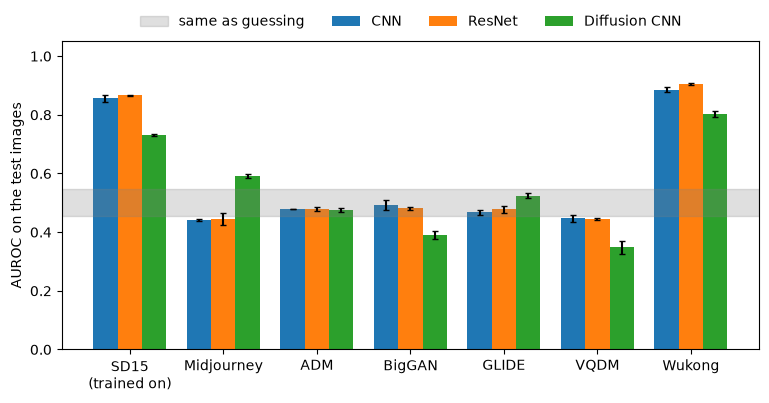

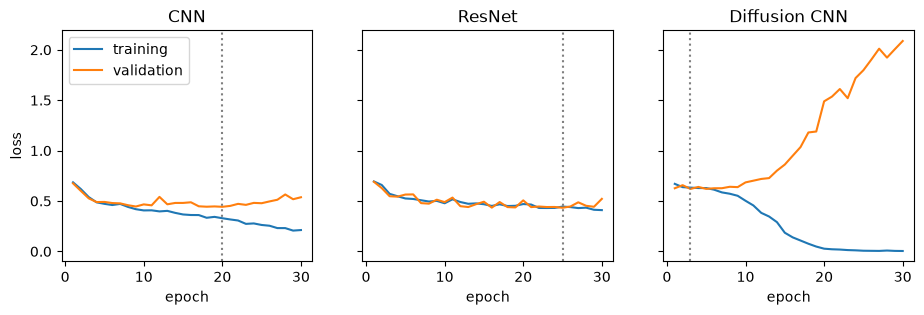

In [114]:
# ---------- Step 11: plots of the results ----------

# AUROC of every model on every generator (error bars = standard deviation over the seeds)
fig, ax = plt.subplots(figsize=(9, 4))
bar = 0.26
positions = np.arange(len(groups))

for k, name in enumerate(models_to_run):
    stds = summary[summary["model"] == name].set_index("generator").loc[groups, "std"]
    ax.bar(positions + (k - 1) * bar, table.loc[name, groups], bar, yerr=stds, capsize=2, label=name)

ax.axhspan(0.5 - band, 0.5 + band, color="grey", alpha=0.25, label="same as guessing")
ax.set_xticks(positions)
ax.set_xticklabels([f"{SEEN}\n(trained on)"] + UNSEEN)
ax.set_ylabel("AUROC on the test images")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4, frameon=False)
plt.savefig(f"{ROOT}/results/figures/04_auroc_by_generator.png", dpi=200, bbox_inches="tight")
plt.show()

# training and validation loss of the final models (seed 0), dotted line = the epoch that was kept
fig, axes = plt.subplots(1, 3, figsize=(11, 3), sharey=True)
for ax, name in zip(axes, models_to_run):
    h = histories[(name, 0)]
    ax.plot(range(1, len(h["train_loss"]) + 1), h["train_loss"], label="training")
    ax.plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], label="validation")
    ax.axvline(h["best_epoch"], color="grey", linestyle=":")
    ax.set_title(name)
    ax.set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].legend()
plt.savefig(f"{ROOT}/results/figures/05_training_curves.png", dpi=200, bbox_inches="tight")
plt.show()

best model on the unseen generators: ResNet


,what,share
0,Real photos wrongly called fake,0.247
1,SD15 fakes correctly called fake,0.803
2,Midjourney fakes correctly called fake,0.247
3,ADM fakes correctly called fake,0.180
4,BigGAN fakes correctly called fake,0.193
5,GLIDE fakes correctly called fake,0.253
6,VQDM fakes correctly called fake,0.157
7,Wukong fakes correctly called fake,0.867


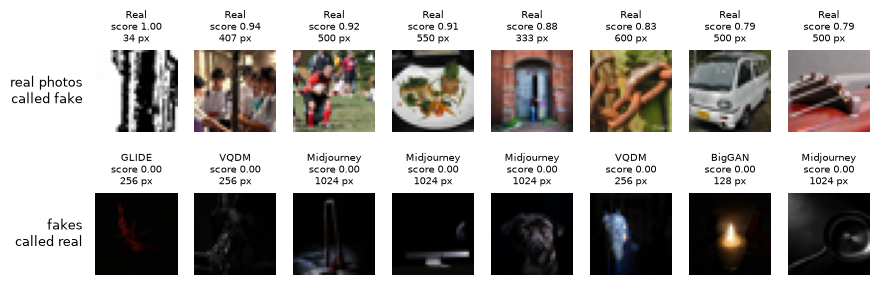

In [115]:
# ---------- Step 12: where does the best model fail? ----------

best_model = table["Unseen mean"].idxmax()
print("best model on the unseen generators:", best_model)

# average the 3 seeds, then use the usual cut-off 0.5 (score >= 0.5 means "fake")
scores = np.mean([predictions[(best_model, s)] for s in cfg["final_seeds"]], axis=0)
is_real = test_gen == "Real"

rates = [("Real photos wrongly called fake", (scores[is_real] >= 0.5).mean())]
for g in groups:
    rates.append((f"{g} fakes correctly called fake", (scores[test_gen == g] >= 0.5).mean()))
rates = pd.DataFrame(rates, columns=["what", "share"])
display(rates.round(3))
rates.to_csv(f"{ROOT}/results/tables/cutoff_rates.csv", index=False)

# the most confident mistakes: real photos with the highest fake score, fakes with the lowest
test_table = df.loc[test_idx].assign(score=scores)
real_called_fake = test_table[(test_table["label"] == 0) & (test_table["score"] >= 0.5)].nlargest(8, "score")
fake_called_real = test_table[(test_table["label"] == 1) & (test_table["score"] < 0.5)].nsmallest(8, "score")

fig, axes = plt.subplots(2, 8, figsize=(10, 3.4))
for row, (mistakes, title) in enumerate([(real_called_fake, "real photos\ncalled fake"), (fake_called_real, "fakes\ncalled real")]):
    for col in range(8):
        axes[row, col].axis("off")
        if col < len(mistakes):
            m = mistakes.iloc[col]
            axes[row, col].imshow(images[mistakes.index[col]])
            axes[row, col].set_title(f"{m['generator']}\nscore {m['score']:.2f}\n{int(m['native_w'])} px", fontsize=7)
    axes[row, 0].text(-0.15, 0.5, title, transform=axes[row, 0].transAxes, ha="right", va="center", fontsize=9)
plt.savefig(f"{ROOT}/results/figures/06_failure_examples.png", dpi=200, bbox_inches="tight")
plt.show()

test_table.drop(columns="split").to_csv(f"{ROOT}/results/tables/best_model_test_scores.csv")

Real          0.0647
SD15          0.0768
Midjourney    0.0645
ADM           0.0586
BigGAN        0.0528
GLIDE         0.0600
VQDM          0.0434
Wukong        0.0932
dtype: float32

logistic regression weights (brightness, contrast, sharpness): [-0.15 -0.38  0.7 ]
ResNet + blur seed 0: best epoch 15 of 30
ResNet + blur seed 1: best epoch 22 of 30
ResNet + blur seed 2: best epoch 28 of 30
ResNet + blur, standard deviation over the seeds:


,SD15,Midjourney,ADM,BigGAN,GLIDE,VQDM,Wukong
0,0.005,0.007,0.007,0.006,0.003,0.008,0.001


mean AUROC:


,SD15,Midjourney,ADM,BigGAN,GLIDE,VQDM,Wukong,Unseen mean,Drop
Sharpness only (sharper = fake),0.631,0.518,0.446,0.366,0.447,0.236,0.789,0.467,0.164
Logistic regression (3 numbers),0.672,0.509,0.452,0.434,0.390,0.318,0.770,0.479,0.193
ResNet,0.866,0.444,0.479,0.481,0.479,0.445,0.904,0.538,0.328
ResNet + blurred copies,0.850,0.434,0.494,0.484,0.465,0.455,0.883,0.536,0.315


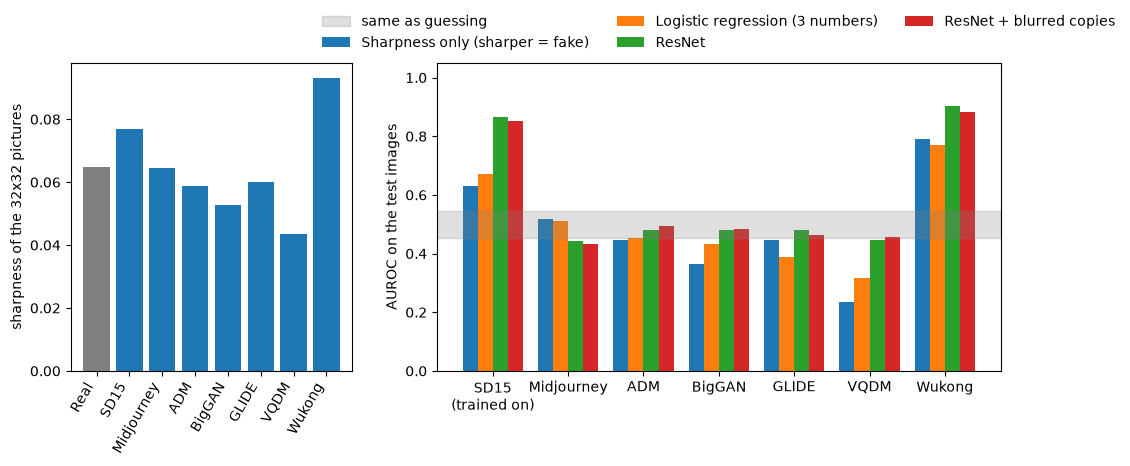

In [116]:
# ---------- Step 13: is it just sharpness? ----------

# In Step 12 the scores seemed to follow how sharp the 32x32 picture is (SD15 and Wukong pictures look sharper,
# VQDM and BigGAN pictures look smoother). Two simple checks:
#   1. detectors without deep learning: sharpness alone, and a logistic regression on three numbers per image
#   2. the same ResNet trained again, with a blurred copy of every training image, so sharpness is a weaker clue

import torch.nn.functional as F
from sklearn.linear_model import LogisticRegression


# three numbers per image: brightness, contrast and sharpness (average difference between neighbouring pixels)
def three_numbers(x):
    bright = x.mean(dim=(1, 2, 3))
    contrast = x.std(dim=(1, 2, 3))
    sharp = ((x[:, :, :, 1:] - x[:, :, :, :-1]).abs().mean(dim=(1, 2, 3))
             + (x[:, :, 1:, :] - x[:, :, :-1, :]).abs().mean(dim=(1, 2, 3))) / 2
    return torch.stack([bright, contrast, sharp], dim=1).numpy()


numbers = three_numbers(pixels)
sharpness = numbers[:, 2]

# average sharpness of every group: which generators are sharper or smoother than the real photos?
sharp_by_group = pd.Series(sharpness).groupby(df["generator"].values).mean().loc[["Real"] + groups]
display(sharp_by_group.round(4))
sharp_by_group.to_csv(f"{ROOT}/results/tables/sharpness_by_group.csv")


# Check 1: logistic regression on the three numbers (scaled with the training images)
scaled = (numbers - numbers[train_idx].mean(axis=0)) / numbers[train_idx].std(axis=0)
lr_model = LogisticRegression().fit(scaled[train_idx], labels[train_idx].numpy())
stats_scores = lr_model.predict_proba(scaled[test_idx])[:, 1]
print("logistic regression weights (brightness, contrast, sharpness):", lr_model.coef_[0].round(2))


# Check 2: a Gaussian blur, then a training set made of the original images plus one blurred copy of each
def blur(x, sigma, size=5):
    ax = torch.arange(size, dtype=torch.float32) - size // 2
    k = torch.exp(-ax ** 2 / (2 * sigma ** 2))
    k = k / k.sum()
    kernel = (k[:, None] * k[None, :]).expand(3, 1, size, size).contiguous()
    return F.conv2d(F.pad(x, (size // 2,) * 4, mode="reflect"), kernel, groups=3)


# every copy gets a random blur strength (the sigmas are in config.yaml)
sigmas = cfg["blur_sigmas"]
strength = torch.randint(len(sigmas), (len(train_idx),), generator=torch.Generator().manual_seed(SEED))
x_train = pixels[train_idx]
x_blurred = x_train.clone()
for j, sigma in enumerate(sigmas):
    x_blurred[strength == j] = blur(x_train[strength == j], sigma)

x_train_blur = torch.cat([x_train, x_blurred])
y_train_blur = torch.cat([labels[train_idx], labels[train_idx]])

# the ResNet again with its best settings from Step 8, 3 seeds (validation images are not blurred)
lr, dropout = float(best.loc["ResNet", "lr"]), float(best.loc["ResNet", "dropout"])
blur_scores = []
for seed in cfg["final_seeds"]:
    model, history = fit(ResNet, dropout, lr, x_train_blur, y_train_blur, pixels[val_idx], labels[val_idx], seed=seed)
    blur_scores.append(predict(model, pixels[test_idx]))
    print(f"ResNet + blur seed {seed}: best epoch {history['best_epoch']} of {cfg['epochs']}")


# AUROC on every group, always against the same real test photos (as in Step 10)
def auroc_by_group(score):
    out = {}
    for g in groups:
        mask = (test_gen == "Real") | (test_gen == g)
        out[g] = roc_auc_score(test_y[mask], score[mask])
    return out


blur_per_seed = pd.DataFrame([auroc_by_group(s) for s in blur_scores], index=cfg["final_seeds"])
blur_per_seed.round(4).to_csv(f"{ROOT}/results/tables/blur_resnet_per_seed.csv")
print("ResNet + blur, standard deviation over the seeds:")
display(blur_per_seed.std().round(3).to_frame().T)

check = pd.DataFrame({
    "Sharpness only (sharper = fake)": auroc_by_group(sharpness[test_idx]),
    "Logistic regression (3 numbers)": auroc_by_group(stats_scores),
    "ResNet": table.loc["ResNet", groups],
    "ResNet + blurred copies": blur_per_seed.mean(),
}).T[groups]
check["Unseen mean"] = check[UNSEEN].mean(axis=1)
check["Drop"] = check[SEEN] - check["Unseen mean"]

print("mean AUROC:")
display(check.round(3))
check.round(4).to_csv(f"{ROOT}/results/tables/sharpness_check.csv")

# figure: sharpness of every group (left) and AUROC of the four detectors (right)
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 2]})

left.bar(sharp_by_group.index, sharp_by_group.values, color=["grey"] + ["C0"] * len(groups))
left.set_ylabel("sharpness of the 32x32 pictures")
plt.setp(left.get_xticklabels(), rotation=60, ha="right")

bar = 0.2
positions = np.arange(len(groups))
for k, name in enumerate(check.index):
    right.bar(positions + (k - 1.5) * bar, check.loc[name, groups], bar, label=name)
right.axhspan(0.5 - band, 0.5 + band, color="grey", alpha=0.25, label="same as guessing")
right.set_xticks(positions)
right.set_xticklabels([f"{SEEN}\n(trained on)"] + UNSEEN)
right.set_ylabel("AUROC on the test images")
right.set_ylim(0, 1.05)
right.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
plt.savefig(f"{ROOT}/results/figures/07_sharpness_check.png", dpi=200, bbox_inches="tight")
plt.show()

In [117]:
# ---------- Step 14: summary ----------

print(f"Models trained on real photos and {SEEN} fakes, tested on {SEEN} and on {len(UNSEEN)} unseen generators.")
print(f"3 seeds per model. AUROC within {0.5 - band:.2f} to {0.5 + band:.2f} is the same as guessing.\n")

for name in table.index:
    clear = int((table.loc[name, UNSEEN] > 0.5 + band).sum())
    print(f"{name}:")
    print(f"   AUROC {table.loc[name, SEEN]:.3f} on {SEEN}, {table.loc[name, 'Unseen mean']:.3f} on the unseen generators "
          f"(drop {table.loc[name, 'Drop']:.3f})")
    print(f"   clearly above guessing on {clear} of {len(UNSEEN)} unseen generators\n")

print("best on", SEEN, ":", table[SEEN].idxmax())
print("best on the unseen generators:", table["Unseen mean"].idxmax())
print("chosen diffusion noise level:", best_t)

print("\nsharpness check, mean AUROC (Step 13):")
for name in check.index:
    print(f"   {name:32s} {check.loc[name, SEEN]:.3f} on {SEEN}, {check.loc[name, 'Unseen mean']:.3f} on the unseen generators")
print("\nall tables are in results/tables/, all figures in results/figures/, weights in models/")

Models trained on real photos and SD15 fakes, tested on SD15 and on 6 unseen generators.
3 seeds per model. AUROC within 0.45 to 0.55 is the same as guessing.

CNN:
   AUROC 0.857 on SD15, 0.536 on the unseen generators (drop 0.321)
   clearly above guessing on 1 of 6 unseen generators

ResNet:
   AUROC 0.866 on SD15, 0.538 on the unseen generators (drop 0.328)
   clearly above guessing on 1 of 6 unseen generators

Diffusion CNN:
   AUROC 0.733 on SD15, 0.522 on the unseen generators (drop 0.210)
   clearly above guessing on 2 of 6 unseen generators

best on SD15 : ResNet
best on the unseen generators: ResNet
chosen diffusion noise level: 400

sharpness check, mean AUROC (Step 13):
   Sharpness only (sharper = fake)  0.631 on SD15, 0.467 on the unseen generators
   Logistic regression (3 numbers)  0.672 on SD15, 0.479 on the unseen generators
   ResNet                           0.866 on SD15, 0.538 on the unseen generators
   ResNet + blurred copies          0.850 on SD15, 0.536 on the